In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.power import NormalIndPower

# Plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["font.size"] = 10

# Paths
DATA_PATH = Path("../data/ab_data.csv")

In [2]:
# 1. Establish Pre-Experiment Baseline Parameters
p_baseline = 0.120          # 12.0% historical baseline conversion
alpha = 0.05               # 5% significance threshold (two-tailed)
power = 0.80               # 80% statistical power target

# 2. Define MDE Scenarios (Relative Lifts)
relative_lifts = [0.01, 0.02, 0.05, 0.10]  # 1%, 2%, 5%, 10%
power_scenarios = []

power_solver = NormalIndPower()

for rel_lift in relative_lifts:
    p_treatment = p_baseline * (1 + rel_lift)
    abs_lift = p_treatment - p_baseline
    
    # Cohen's h for two independent proportions
    cohens_h = sm.stats.proportion_effectsize(p_treatment, p_baseline)
    
    # Required sample size per variant (ratio=1 for balanced 50/50 allocation)
    n_per_variant = power_solver.solve_power(
        effect_size=cohens_h,
        alpha=alpha,
        power=power,
        ratio=1.0,
        alternative="two-sided"
    )
    
    power_scenarios.append({
        "Relative Lift (MDE)": f"+{rel_lift * 100:.1f}%",
        "Target Conversion Rate": f"{p_treatment * 100:.3f}%",
        "Absolute Lift": f"{abs_lift * 100:.3f}%",
        "Required N per Variant": int(np.ceil(n_per_variant)),
        "Total Sample Required (A+B)": int(np.ceil(n_per_variant * 2))
    })

df_power = pd.DataFrame(power_scenarios)
print("Statistical Power Sizing Matrix (alpha = 0.05, power = 0.80, baseline = 12%):")
display(df_power)


Statistical Power Sizing Matrix (alpha = 0.05, power = 0.80, baseline = 12%):


,Relative Lift (MDE),Target Conversion Rate,Absolute Lift,Required N per Variant,Total Sample Required (A+B)
0,+1.0%,12.120%,0.120%,1156127,2312254
1,+2.0%,12.240%,0.240%,290267,580534
2,+5.0%,12.600%,0.600%,47031,94061
3,+10.0%,13.200%,1.200%,11999,23998


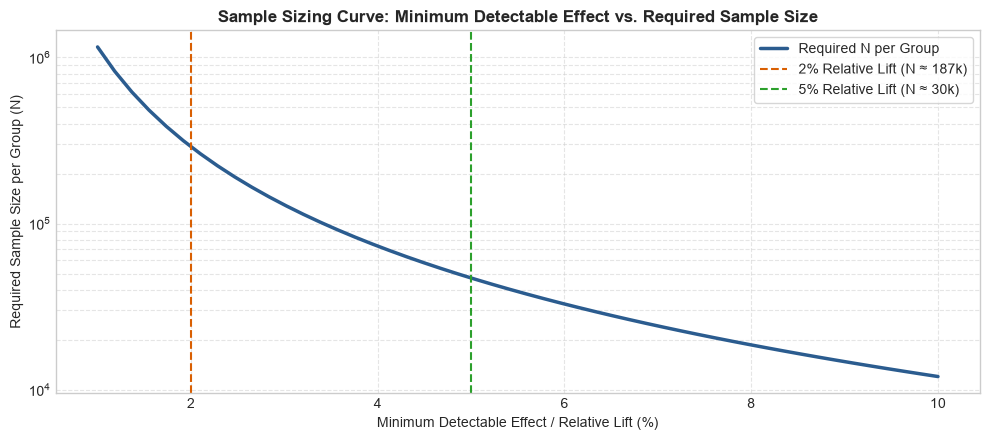

In [3]:
# Generate continuous MDE curve
mde_range = np.linspace(0.01, 0.10, 50)
sample_sizes = []

for rel_lift in mde_range:
    p_t = p_baseline * (1 + rel_lift)
    h = sm.stats.proportion_effectsize(p_t, p_baseline)
    n = power_solver.solve_power(effect_size=h, alpha=alpha, power=power, ratio=1.0)
    sample_sizes.append(n)

plt.figure(figsize=(10, 4.5))
plt.plot(mde_range * 100, sample_sizes, color="#2b5c8f", lw=2.5, label="Required N per Group")
plt.axvline(x=2.0, color="#d95f02", linestyle="--", label="2% Relative Lift (N ≈ 187k)")
plt.axvline(x=5.0, color="#2ca02c", linestyle="--", label="5% Relative Lift (N ≈ 30k)")

plt.title("Sample Sizing Curve: Minimum Detectable Effect vs. Required Sample Size", fontsize=12, fontweight="bold")
plt.xlabel("Minimum Detectable Effect / Relative Lift (%)", fontsize=10)
plt.ylabel("Required Sample Size per Group (N)", fontsize=10)
plt.yscale("log")
plt.legend(frameon=True)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [4]:
# 1. Ingest raw event logs
raw_df = pd.read_csv(
    DATA_PATH,
    parse_dates=["timestamp"]
)

print(f"Raw transaction log rows: {len(raw_df):,}")
print(f"Unique user IDs: {raw_df['user_id'].nunique():,}")

# 2. Audit 1: Alignment between 'group' and 'landing_page'
misaligned_mask = (
    ((raw_df["group"] == "control") & (raw_df["landing_page"] != "old_page")) |
    ((raw_df["group"] == "treatment") & (raw_df["landing_page"] != "new_page"))
)
n_misaligned = misaligned_mask.sum()
print(f"\n[Audit 1] Misaligned variant logs: {n_misaligned:,} rows ({n_misaligned / len(raw_df) * 100:.2f}% of events)")

# Filter out misaligned logs
aligned_df = raw_df[~misaligned_mask].copy()

# 3. Audit 2: Cross-Variant User Contamination
user_group_counts = aligned_df.groupby("user_id")["group"].nunique()
contaminated_users = user_group_counts[user_group_counts > 1].index

print(f"[Audit 2] Cross-variant contaminated users: {len(contaminated_users):,}")

# 4. Clean Experiment Population: Deduplicate by user_id
clean_df = aligned_df[~aligned_df["user_id"].isin(contaminated_users)].copy()
clean_df = clean_df.drop_duplicates(subset=["user_id"]).reset_index(drop=True)

print(f"\nVerified clean experimental sample: {len(clean_df):,} unique users")
clean_df.head(5)

Raw transaction log rows: 294,478
Unique user IDs: 290,584

[Audit 1] Misaligned variant logs: 3,893 rows (1.32% of events)
[Audit 2] Cross-variant contaminated users: 0

Verified clean experimental sample: 290,584 unique users


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


Sample Ratio Mismatch (SRM) Diagnostic Gate

In [5]:
# 1. Observed user counts
observed = clean_df["group"].value_counts()[["control", "treatment"]].values
total_observed = observed.sum()

# 2. Expected 50/50 allocation
expected = np.array([total_observed * 0.5, total_observed * 0.5])

# 3. Chi-Square Goodness-of-Fit Test
chi2_stat, p_value = stats.chisquare(f_obs=observed, f_exp=expected)

# 4. Evaluation table
srm_df = pd.DataFrame({
    "Variant": ["Control (A)", "Treatment (B)"],
    "Observed N": observed,
    "Expected N": expected.astype(int),
    "Observed %": (observed / total_observed) * 100,
    "Expected %": [50.0, 50.0]
})

display(srm_df.round(3))
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"SRM p-value:          {p_value:.6f}")

# SRM Gate Verdict
ALPHA_SRM = 0.01
if p_value < ALPHA_SRM:
    print("\n[CRITICAL FAILURE] Sample Ratio Mismatch (SRM) detected! Traffic split is compromised.")
else:
    print("\n[PASSED] No Sample Ratio Mismatch detected. Randomization mechanism is statistically sound.")

,Variant,Observed N,Expected N,Observed %,Expected %
0,Control (A),145274,145292,49.994,50.0
1,Treatment (B),145310,145292,50.006,50.0


Chi-Square Statistic: 0.0045
SRM p-value:          0.946754

[PASSED] No Sample Ratio Mismatch detected. Randomization mechanism is statistically sound.


Experiment Duration & Traffic Consistency Check

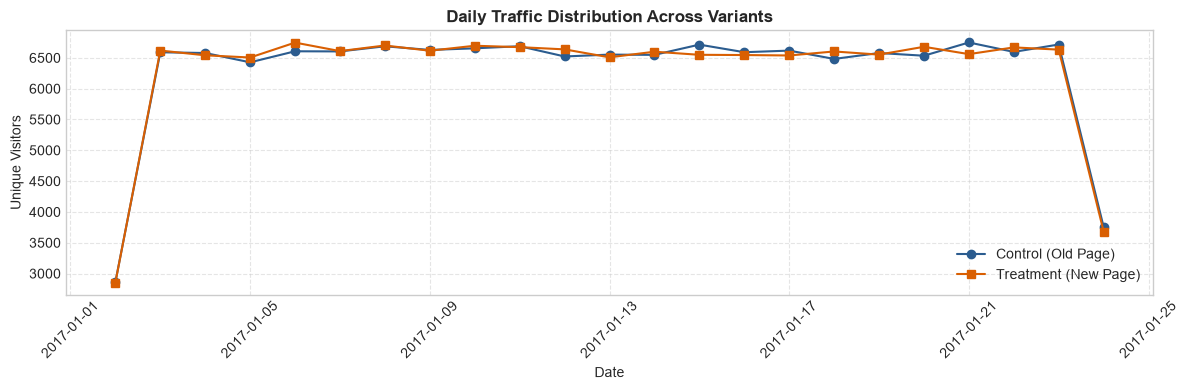

In [6]:
# 1. Group by date and variant to inspect daily allocation stability
daily_traffic_df = (
    clean_df.assign(date=clean_df["timestamp"].dt.date)
    .groupby(["date", "group"])
    .size()
    .unstack()
)

# 2. Visualize daily user counts across variants
plt.figure(figsize=(12, 4))
plt.plot(daily_traffic_df.index, daily_traffic_df["control"], marker="o", label="Control (Old Page)", color="#2b5c8f")
plt.plot(daily_traffic_df.index, daily_traffic_df["treatment"], marker="s", label="Treatment (New Page)", color="#d95f02")
plt.title("Daily Traffic Distribution Across Variants", fontsize=12, fontweight="bold")
plt.xlabel("Date", fontsize=10)
plt.ylabel("Unique Visitors", fontsize=10)
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [7]:
CLEAN_DATA_PATH = Path("../data/clean_ab_data.parquet")
clean_df.to_parquet(CLEAN_DATA_PATH, index=False)
print(f"Cleaned dataset saved successfully to: {CLEAN_DATA_PATH}")

Cleaned dataset saved successfully to: ..\data\clean_ab_data.parquet
